# Bangla Multimodal Fake News: Model Training

This notebook extracts features and trains the models. It needs a **T4 GPU**: Runtime > Change runtime type > T4 GPU.

Run `01_preprocessing.ipynb` first, so that `unified_split.csv` exists on Drive.

In [1]:
from google.colab import drive
drive.mount("/content/drive")

Mounted at /content/drive


## 1. Unpack the project code

In [2]:
import shutil
import zipfile
from pathlib import Path

DRIVE_ROOT = Path("/content/drive/MyDrive")
CODE_DIR = Path("/content/Bangla-Multimodal-FakeNews")

candidates = list(DRIVE_ROOT.glob("Bangla-Multimodal-FakeNews*.zip")) + list(
    (DRIVE_ROOT / "BFND-data").glob("Bangla-Multimodal-FakeNews*.zip")
)
assert candidates, "Code zip not found on Drive. Upload Bangla-Multimodal-FakeNews.zip first."
ZIP = max(candidates, key=lambda p: p.stat().st_mtime)
print("Using zip:", ZIP)

shutil.rmtree(CODE_DIR, ignore_errors=True)   # remove any old copy so stale code cannot run
with zipfile.ZipFile(ZIP) as z:
    z.extractall("/content")
print("Files in zip:", len(zipfile.ZipFile(ZIP).namelist()))

Using zip: /content/drive/MyDrive/Bangla-Multimodal-FakeNews.zip
Files in zip: 36


In [3]:
import os
from pathlib import Path

os.chdir(CODE_DIR)
config_text = Path("configs/config.py").read_text(encoding="utf-8")
assert "CLIP_IMAGE_MODEL" in config_text, (
    "Old code detected. Upload the latest zip to Drive, then run the unpack cell again."
)
print("Code version OK. Working directory:", os.getcwd())

Code version OK. Working directory: /content/Bangla-Multimodal-FakeNews


## 2. Check the GPU

## 3. Install packages

In [4]:
!pip install -q "accelerate>=0.26" "transformers>=4.46" "sentence-transformers>=3.0" "rank-bm25>=0.2.2" joblib openpyxl

## 4. Preflight

In [5]:
!python scripts/00_preflight.py

[OK]   Hugging Face model: csebuetnlp/banglabert
[OK]   Hugging Face model: sentence-transformers/clip-ViT-B-32
[OK]   Hugging Face model: sentence-transformers/clip-ViT-B-32-multilingual-v1
[OK]   Hugging Face model: intfloat/multilingual-e5-base
[OK]   Hugging Face model: MoritzLaurer/mDeBERTa-v3-base-xnli-multilingual-nli-2mil7
[WARN] btmd_schema.py: 'source_url_col' is not set; related features/guards will be skipped
[OK]   btmd_schema.py: required fields are filled in
[OK]   BTMD slim data: /content/drive/MyDrive/BFND-data/data/raw
[MISS] evidence.csv: /content/drive/MyDrive/BFND-data/data/evidence/evidence.csv
[MISS] cultural_annotations.csv: /content/drive/MyDrive/BFND-data/data/annotations/cultural_annotations.csv
[MISS] claim_evidence_pairs.csv: /content/drive/MyDrive/BFND-data/data/annotations/claim_evidence_pairs.csv
[OK]   GPU: Tesla T4

Experiments that can run:
  E1  BanglaBERT fine-tune (text)         : runs on BTMD alone
  E1f/E2/E3 frozen features + MLP          : runs

## 5. Feature extraction

Builds BanglaBERT embeddings and CLIP image and text embeddings. The cultural and evidence features are built only when their input files exist; otherwise a [SKIP] line is printed.

In [ ]:
!python scripts/02_extract_features.py

## 6. Check the feature files

Expected shapes: `bert (3910, 768)`, `clip_img (3910, 512)`, `clip_txt (3910, 512)`, `sim (3910, 1)`. The row count changes if the data changes.

In [7]:
import numpy as np
import pandas as pd
from configs.config import FEATURE_DIR

meta = pd.read_csv(FEATURE_DIR / "meta.csv")
print(meta["split"].value_counts())
for name in ["bert", "clip_img", "clip_txt", "sim"]:
    print(name, np.load(FEATURE_DIR / f"{name}.npy").shape)

split
train    2736
test      588
val       586
Name: count, dtype: int64
bert (3910, 768)
clip_img (3910, 512)
clip_txt (3910, 512)
sim (3910, 1)


## 7. Length-only baseline

A model that sees only the text length. If it scores close to the real models, those models may be relying on length, so their results need careful reading.

In [ ]:
import numpy as np
import pandas as pd
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import f1_score

from configs.config import FEATURE_DIR

meta = pd.read_csv(FEATURE_DIR / "meta.csv")
meta["n_chars"] = meta["model_text"].astype(str).str.len()
X_len = np.log1p(meta[["n_chars"]].to_numpy(dtype=float))
train_mask = meta["split"].eq("train").to_numpy()
test_mask = meta["split"].eq("test").to_numpy()
y = meta["y"].astype(int).to_numpy()

clf = LogisticRegression(max_iter=1000, class_weight="balanced")
clf.fit(X_len[train_mask], y[train_mask])
pred = clf.predict(X_len[test_mask])
print("Length-only accuracy (test):", round((pred == y[test_mask]).mean(), 4))
print("Length-only macro-F1 (test):", round(f1_score(y[test_mask], pred, average="macro"), 4))

## 8. E1: fine-tune BanglaBERT (text only)

Runs three seeds. Expect a long run.

In [9]:
!python scripts/03_train_text_baseline.py

Loading weights: 100% 197/197 [00:00<00:00, 25001.60it/s]
[transformers] ElectraForSequenceClassification LOAD REPORT from: csebuetnlp/banglabert
Key                                               | Status     | 
--------------------------------------------------+------------+-
discriminator_predictions.dense.weight            | UNEXPECTED | 
discriminator_predictions.dense_prediction.bias   | UNEXPECTED | 
discriminator_predictions.dense.bias              | UNEXPECTED | 
discriminator_predictions.dense_prediction.weight | UNEXPECTED | 
classifier.out_proj.bias                          | MISSING    | 
classifier.dense.bias                             | MISSING    | 
classifier.out_proj.weight                        | MISSING    | 
classifier.dense.weight                           | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the c

## 9. Fusion experiments, decision layer and evidence check

In [ ]:
!python scripts/04_train_fusion.py

In [12]:
import time
from configs.config import RESULTS_DIR

for p in sorted(RESULTS_DIR.glob("*")):
    print(p.name, time.ctime(p.stat().st_mtime))

e1_text_only.json Tue Nov 17 17:50:12 2026
fusion_results.json Tue Nov 17 17:50:41 2026
summary.md Tue Nov 17 17:50:41 2026


## 10. Summary

In [11]:
from configs.config import RESULTS_DIR

print((RESULTS_DIR / "summary.md").read_text(encoding="utf-8"))

| Experiment | Features | Accuracy (mean ± std) | Macro-F1 (mean ± std) |
|---|---|---|---|
| E1_banglabert_finetuned | text (fine-tuned) | 0.8095 ± 0.0084 | 0.5457 ± 0.0057 |
| E1f_frozen_banglabert_mlp | bert | 0.7744 ± 0.0129 | 0.6271 ± 0.0277 |
| E2_clip_image_only | clip_img | 0.6009 ± 0.0049 | 0.5413 ± 0.0102 |
| E3_banglabert_clip | bert, clip_img, clip_txt, sim | 0.8373 ± 0.0056 | 0.7448 ± 0.0158 |



label    acc  acc_std     f1  f1_std
   E1 0.8095   0.0084 0.5457  0.0057
  E1f 0.7744   0.0129 0.6271  0.0277
   E2 0.6009   0.0049 0.5413  0.0102
   E3 0.8373   0.0056 0.7448  0.0158


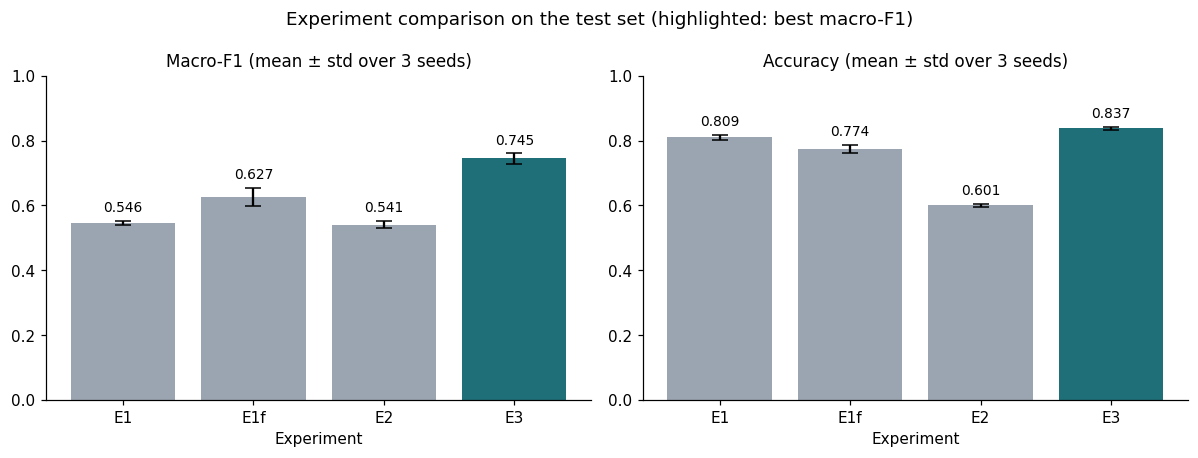

Experiments with confusion matrices: ['E1', 'E1f', 'E2', 'E3']


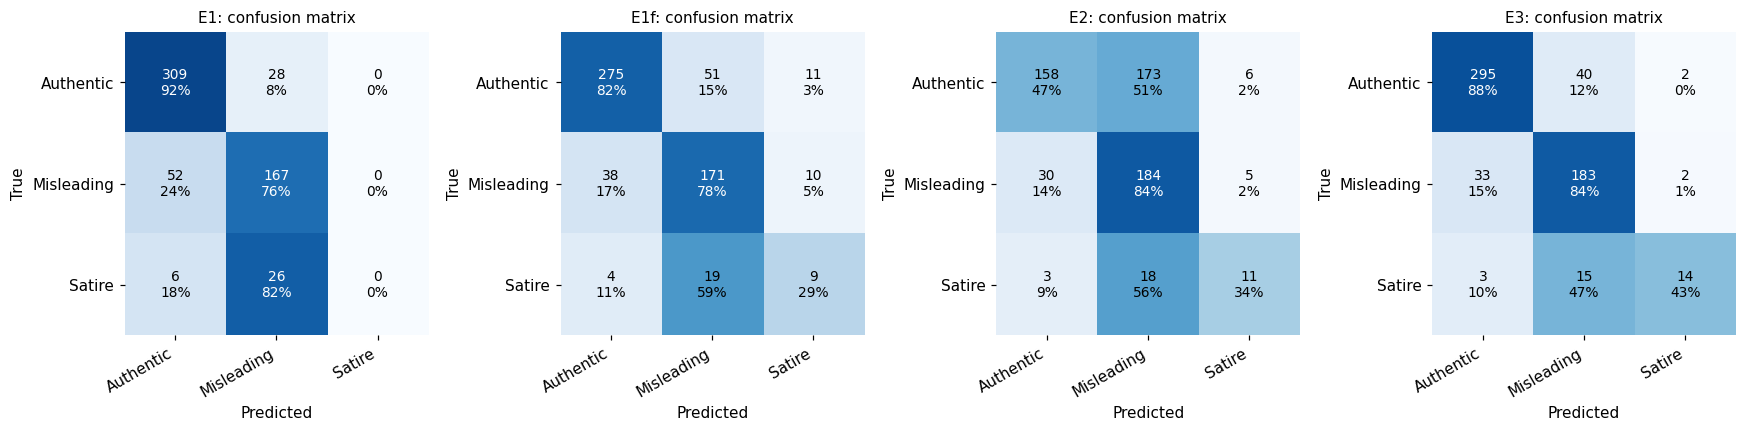

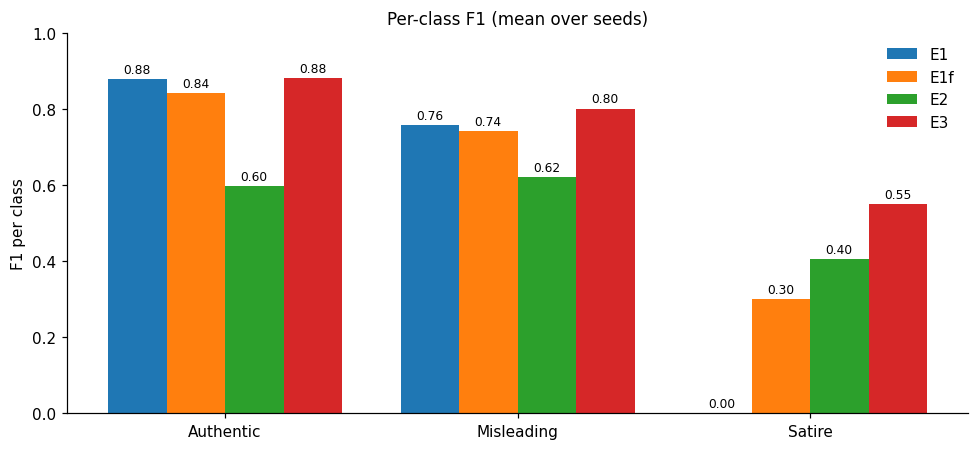

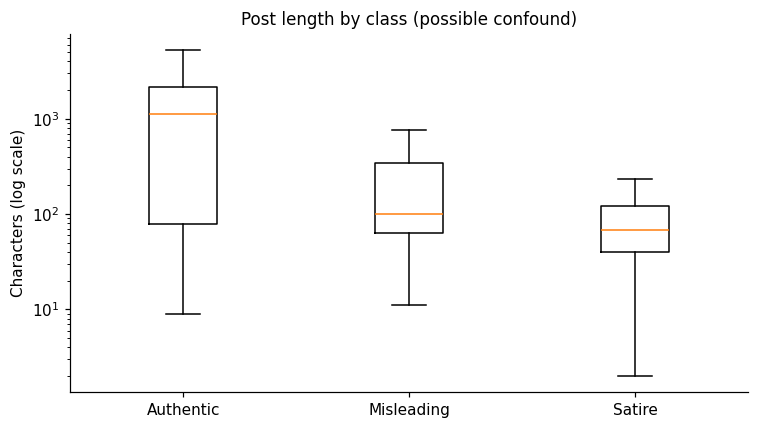

Figures saved to: /content/drive/MyDrive/BFND-data/results/figures


In [13]:
# Highlight results with graphs. Reads the saved results, trains nothing.
import json
import re

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from configs.config import FEATURE_DIR, LABELS_3, RESULTS_DIR

FIG_DIR = RESULTS_DIR / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
BASE_COLOR = "#9aa5b1"
HIGHLIGHT = "#1f6f78"


def parse_summary(path):
    """Read the experiment rows of summary.md, e.g. '| E3_... | ... | 0.8373 ± 0.0056 | ... |'."""
    records = []
    for line in path.read_text(encoding="utf-8").splitlines():
        cells = [c.strip() for c in line.strip().strip("|").split("|")]
        if len(cells) != 4 or not re.match(r"^E\d", cells[0]):
            continue
        acc, acc_std = (float(x) for x in re.findall(r"\d+\.\d+", cells[2]))
        f1, f1_std = (float(x) for x in re.findall(r"\d+\.\d+", cells[3]))
        records.append({"label": cells[0].split("_")[0], "acc": acc, "acc_std": acc_std,
                        "f1": f1, "f1_std": f1_std})
    return pd.DataFrame(records)


def find_confusion_matrices(obj, path=""):
    """Walk any JSON structure and collect every 'confusion_matrix' with its location."""
    found = []
    if isinstance(obj, dict):
        for key, value in obj.items():
            if key == "confusion_matrix":
                found.append((path, np.array(value, dtype=float)))
            else:
                found += find_confusion_matrices(value, f"{path}/{key}" if path else key)
    elif isinstance(obj, list):
        for i, value in enumerate(obj):
            found += find_confusion_matrices(value, f"{path}[{i}]")
    return found


def per_class_f1(cm):
    tp = np.diag(cm)
    precision = tp / np.clip(cm.sum(axis=0), 1e-9, None)
    recall = tp / np.clip(cm.sum(axis=1), 1e-9, None)
    return 2 * precision * recall / np.clip(precision + recall, 1e-9, None)


# ---- Graph 1: accuracy and macro-F1 with error bars ----
summary = parse_summary(RESULTS_DIR / "summary.md")
print(summary.round(4).to_string(index=False))

best_idx = summary["f1"].idxmax()
fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))
for ax, metric, title in zip(axes, ["f1", "acc"], ["Macro-F1", "Accuracy"]):
    colors = [HIGHLIGHT if i == best_idx else BASE_COLOR for i in summary.index]
    bars = ax.bar(summary["label"], summary[metric], yerr=summary[metric + "_std"],
                  capsize=5, color=colors)
    ax.bar_label(bars, fmt="%.3f", padding=4, fontsize=9)
    ax.set_ylim(0, 1)
    ax.set_title(f"{title} (mean ± std over 3 seeds)", fontsize=11)
    ax.set_xlabel("Experiment")
fig.suptitle("Experiment comparison on the test set (highlighted: best macro-F1)", fontsize=12)
fig.tight_layout()
fig.savefig(FIG_DIR / "01_experiment_comparison.png", dpi=200, bbox_inches="tight")
plt.show()

# ---- Collect confusion matrices from the saved JSON files ----
groups = {}
e1 = json.loads((RESULTS_DIR / "e1_text_only.json").read_text(encoding="utf-8"))
groups["E1"] = [cm for _, cm in find_confusion_matrices(e1)]

fusion = json.loads((RESULTS_DIR / "fusion_results.json").read_text(encoding="utf-8"))
for path, cm in find_confusion_matrices(fusion):
    label = path.split("/")[0].split("_")[0]
    if label == "E1" or not re.match(r"^E\d", label) or cm.shape != (3, 3):
        continue  # E1 is already read from its own file; keep only 3-class experiments
    groups.setdefault(label, []).append(cm)

groups = {k: np.mean(v, axis=0) for k, v in groups.items() if v and v[0].shape == (3, 3)}
print("Experiments with confusion matrices:", list(groups.keys()))

# ---- Graph 2: confusion matrices (counts and row percentages) ----
if groups:
    ncols = min(len(groups), 4)
    nrows = int(np.ceil(len(groups) / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=(4 * ncols, 3.8 * nrows), squeeze=False)
    for ax in axes.ravel():
        ax.set_visible(False)
    for ax, (name, cm) in zip(axes.ravel(), groups.items()):
        ax.set_visible(True)
        row_pct = cm / cm.sum(axis=1, keepdims=True)
        ax.imshow(row_pct, cmap="Blues", vmin=0, vmax=1)
        for i in range(3):
            for j in range(3):
                color = "white" if row_pct[i, j] > 0.6 else "black"
                ax.text(j, i, f"{cm[i, j]:.0f}\n{row_pct[i, j]:.0%}", ha="center",
                        va="center", color=color, fontsize=9)
        ax.set_xticks(range(3), LABELS_3, rotation=30, ha="right")
        ax.set_yticks(range(3), LABELS_3)
        ax.set_xlabel("Predicted")
        ax.set_ylabel("True")
        ax.set_title(f"{name}: confusion matrix", fontsize=10)
        for spine in ax.spines.values():
            spine.set_visible(False)
    fig.tight_layout()
    fig.savefig(FIG_DIR / "02_confusion_matrices.png", dpi=200, bbox_inches="tight")
    plt.show()

    # ---- Graph 3: per-class F1 ----
    x = np.arange(len(LABELS_3))
    width = 0.8 / len(groups)
    fig, ax = plt.subplots(figsize=(9, 4.2))
    for i, (name, cm) in enumerate(groups.items()):
        offset = (i - (len(groups) - 1) / 2) * width
        bars = ax.bar(x + offset, per_class_f1(cm), width, label=name)
        ax.bar_label(bars, fmt="%.2f", fontsize=8, padding=2)
    ax.set_xticks(x, LABELS_3)
    ax.set_ylim(0, 1)
    ax.set_ylabel("F1 per class")
    ax.set_title("Per-class F1 (mean over seeds)", fontsize=11)
    ax.legend(frameon=False)
    fig.tight_layout()
    fig.savefig(FIG_DIR / "03_per_class_f1.png", dpi=200, bbox_inches="tight")
    plt.show()

# ---- Graph 4: post length by class (length confound) ----
meta = pd.read_csv(FEATURE_DIR / "meta.csv")
meta["n_chars"] = meta["model_text"].astype(str).str.len()
data = [meta.loc[meta["label"] == c, "n_chars"].to_numpy() for c in LABELS_3]
fig, ax = plt.subplots(figsize=(7, 4))
ax.boxplot(data, showfliers=False)
ax.set_xticks(range(1, len(LABELS_3) + 1), LABELS_3)
ax.set_yscale("log")
ax.set_ylabel("Characters (log scale)")
ax.set_title("Post length by class (possible confound)", fontsize=11)
fig.tight_layout()
fig.savefig(FIG_DIR / "04_length_by_class.png", dpi=200, bbox_inches="tight")
plt.show()

print("Figures saved to:", FIG_DIR)